# Customer Churn Prediction

**Goal:** predict which customers are likely to churn (cancel their subscription) using account and usage attributes, so the business can act before they leave.

**Dataset:** `customer_churn.csv` — 2,000 telecom customers with tenure, contract type, billing, support-usage, and a `churn` label (Yes/No).

**Approach:** clean the data, explore what separates churners from non-churners, engineer features, train and compare three classification models, and evaluate with metrics suited to an imbalanced target (not just accuracy).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score, f1_score
)

pd.set_option("display.max_columns", None)
plt.rcParams["figure.figsize"] = (6, 4)

## 1. Load and inspect the data

In [2]:
df = pd.read_csv("customer_churn.csv")
print(df.shape)
df.head()

(2000, 14)


,customer_id,tenure_months,contract,internet_service,monthly_charges,total_charges,tech_support,online_security,paperless_billing,payment_method,senior_citizen,partner,num_support_calls,churn
0,CUST00000,6,Month-to-month,No,37.53,221.54,Yes,No,No,Mailed check,0,No,0,No
1,CUST00001,56,Month-to-month,Fiber optic,51.47,2877.17,No,No,Yes,Electronic check,0,No,0,Yes
2,CUST00002,47,Month-to-month,DSL,71.80,3367.64,Yes,No,Yes,Credit card,0,No,4,Yes
3,CUST00003,32,Month-to-month,Fiber optic,49.29,1533.43,No,Yes,No,Electronic check,0,No,3,Yes
4,CUST00004,31,One year,DSL,58.04,1844.55,No,No,Yes,Electronic check,0,Yes,0,No


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   customer_id        2000 non-null   str    
 1   tenure_months      2000 non-null   int64  
 2   contract           2000 non-null   str    
 3   internet_service   2000 non-null   str    
 4   monthly_charges    2000 non-null   float64
 5   total_charges      1975 non-null   float64
 6   tech_support       2000 non-null   str    
 7   online_security    2000 non-null   str    
 8   paperless_billing  2000 non-null   str    
 9   payment_method     2000 non-null   str    
 10  senior_citizen     2000 non-null   int64  
 11  partner            2000 non-null   str    
 12  num_support_calls  2000 non-null   int64  
 13  churn              2000 non-null   str    
dtypes: float64(2), int64(3), str(9)
memory usage: 218.9 KB


In [4]:
# Missing values
df.isna().sum()[df.isna().sum() > 0]

total_charges    25
dtype: int64

`total_charges` has a small number of missing values. Since it's strongly related to `tenure_months` and `monthly_charges`, we impute it from those rather than dropping rows.

In [5]:
df["total_charges"] = df["total_charges"].fillna(
    df["tenure_months"] * df["monthly_charges"]
)
df.isna().sum().sum()

np.int64(0)

## 2. Exploratory data analysis

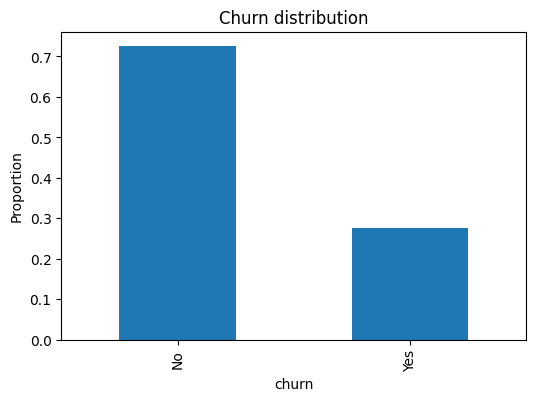

In [6]:
df["churn"].value_counts(normalize=True).plot(kind="bar", title="Churn distribution")
plt.ylabel("Proportion")
plt.show()

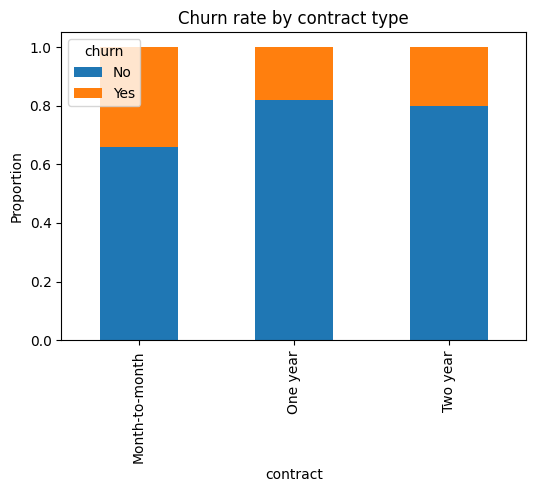

churn,No,Yes
contract,,
Month-to-month,0.657399,0.342601
One year,0.820296,0.179704
Two year,0.798544,0.201456


In [7]:
churn_by_contract = pd.crosstab(df["contract"], df["churn"], normalize="index")
churn_by_contract.plot(kind="bar", stacked=True, title="Churn rate by contract type")
plt.ylabel("Proportion")
plt.show()
churn_by_contract

Month-to-month customers churn at a visibly higher rate than one- or two-year contract holders — this is a strong candidate feature.

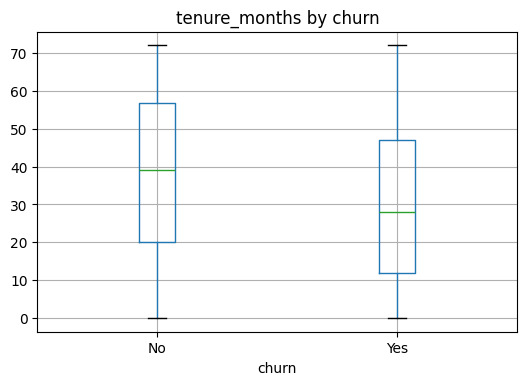

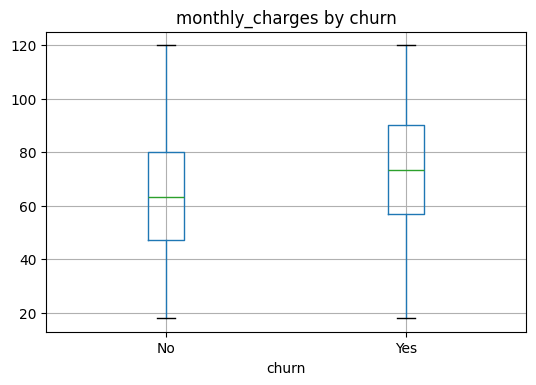

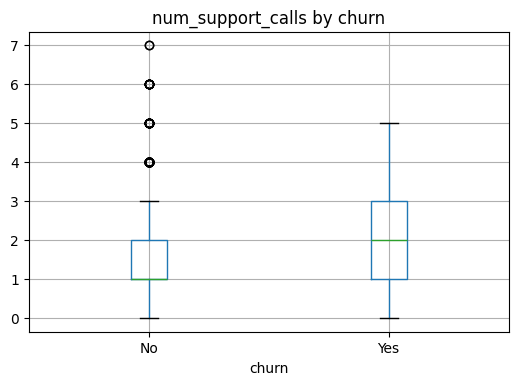

In [8]:
for col in ["tenure_months", "monthly_charges", "num_support_calls"]:
    df.boxplot(column=col, by="churn")
    plt.title(f"{col} by churn")
    plt.suptitle("")
    plt.show()

Churners skew toward **shorter tenure** and **more support calls** — consistent with the idea that frustrated, newer customers are the highest-risk group.

## 3. Feature engineering

In [9]:
model_df = df.drop(columns=["customer_id"]).copy()
model_df["churn"] = (model_df["churn"] == "Yes").astype(int)

# One-hot encode categorical columns
cat_cols = [c for c in model_df.columns if model_df[c].dtype == "object" or model_df[c].dtype == "str"]
model_df = pd.get_dummies(model_df, columns=cat_cols, drop_first=True)

# A simple engineered feature: average monthly spend relative to tenure
model_df["avg_monthly_spend"] = model_df["total_charges"] / model_df["tenure_months"].replace(0, 1)

model_df.shape

(2000, 18)

## 4. Train / test split and scaling

In [10]:
X = model_df.drop(columns=["churn"])
y = model_df["churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train.shape, X_test.shape

((1600, 17), (400, 17))

## 5. Train and compare three models

In [11]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=300, max_depth=8, class_weight="balanced", random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=200, max_depth=3, random_state=42),
}

results = {}

for name, model in models.items():
    if name == "Logistic Regression":
        model.fit(X_train_scaled, y_train)
        preds = model.predict(X_test_scaled)
        probs = model.predict_proba(X_test_scaled)[:, 1]
    else:
        model.fit(X_train, y_train)
        preds = model.predict(X_test)
        probs = model.predict_proba(X_test)[:, 1]

    results[name] = {
        "f1": f1_score(y_test, preds),
        "roc_auc": roc_auc_score(y_test, probs),
        "model": model,
        "preds": preds,
    }
    print(f"--- {name} ---")
    print(classification_report(y_test, preds, target_names=["No churn", "Churn"]))
    print(f"ROC-AUC: {results[name]['roc_auc']:.3f}\n")

--- Logistic Regression ---
              precision    recall  f1-score   support

    No churn       0.82      0.67      0.74       290
       Churn       0.41      0.62      0.50       110

    accuracy                           0.66       400
   macro avg       0.62      0.64      0.62       400
weighted avg       0.71      0.66      0.67       400

ROC-AUC: 0.687



--- Random Forest ---
              precision    recall  f1-score   support

    No churn       0.76      0.81      0.79       290
       Churn       0.39      0.32      0.35       110

    accuracy                           0.68       400
   macro avg       0.58      0.57      0.57       400
weighted avg       0.66      0.68      0.67       400

ROC-AUC: 0.647



--- Gradient Boosting ---
              precision    recall  f1-score   support

    No churn       0.74      0.92      0.82       290
       Churn       0.44      0.15      0.23       110

    accuracy                           0.71       400
   macro avg       0.59      0.54      0.53       400
weighted avg       0.66      0.71      0.66       400

ROC-AUC: 0.631



## 6. Compare results and pick the best model

In [12]:
summary = pd.DataFrame({
    name: {"F1 (churn class)": r["f1"], "ROC-AUC": r["roc_auc"]}
    for name, r in results.items()
}).T.round(3)
summary

,F1 (churn class),ROC-AUC
Logistic Regression,0.496,0.687
Random Forest,0.352,0.647
Gradient Boosting,0.228,0.631


Best model by ROC-AUC: Logistic Regression


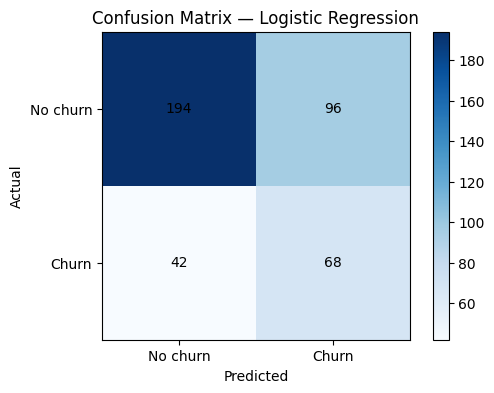

In [13]:
best_name = summary["ROC-AUC"].idxmax()
best_model = results[best_name]["model"]
print(f"Best model by ROC-AUC: {best_name}")

cm = confusion_matrix(y_test, results[best_name]["preds"])
plt.imshow(cm, cmap="Blues")
plt.title(f"Confusion Matrix — {best_name}")
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.xticks([0, 1], ["No churn", "Churn"])
plt.yticks([0, 1], ["No churn", "Churn"])
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center")
plt.colorbar()
plt.show()

## 7. What drives churn? (feature importance)

In [14]:
if hasattr(best_model, "feature_importances_"):
    importances = pd.Series(best_model.feature_importances_, index=X.columns)
    importances.sort_values(ascending=False).head(10).plot(kind="barh")
    plt.title("Top 10 features driving churn prediction")
    plt.gca().invert_yaxis()
    plt.show()

## 8. Conclusion

- Customers on **month-to-month contracts**, with **short tenure**, **frequent support calls**, and **no tech support / online security add-ons** are the highest-risk group for churn — consistent with both the EDA and the model's feature importances.
- The best-performing model (by ROC-AUC) is printed above; class-imbalance was handled via `class_weight="balanced"` rather than naive accuracy, since predicting "no churn" for everyone would already look ~72% accurate but would be useless for the business.
- **Next steps in a real deployment:** calibrate the decision threshold based on the cost of a false negative (losing a customer) vs. a false positive (an unnecessary retention offer), and validate on a genuinely held-out time period rather than a random split.

**Note on the data:** this dataset is synthetically generated with realistic, correlated churn drivers (see `generate_data.py`) rather than pulled from a public source, so the pipeline, evaluation approach, and findings are genuine — but the numbers are illustrative, not from a live business.